<a href="https://colab.research.google.com/github/mhabibier/Practical-Statistics-for-Data-Scientists/blob/main/07_Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mhabibier/Practical-Statistics-for-Data-Scientists/blob/main/07_Unsupervised_Learning.ipynb)

# Chapter 7 — Unsupervised Learning

**Buku:** *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, edisi kedua (2020), Peter Bruce, Andrew Bruce, Peter Gedeck, O'Reilly Media.  
**Mahasiswa:** Muhammad Habibie Rabbani · TK-47-04 · Teknik Komputer, Telkom University.  
**Jenis pekerjaan:** reproduksi/adaptasi kode pendamping resmi, penjelasan teori berbahasa Indonesia, dan analisis tambahan.  
**Sumber kode:** [repository penulis pada commit tetap](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa); hak cipta kode sumber © 2019 Peter C. Bruce, Andrew Bruce, Peter Gedeck, GPL-3.0 (lihat `LICENSE` dan `THIRD_PARTY_NOTICES.md`).

Jalankan setiap sel dari atas ke bawah dalam sesi baru. Output disertakan sebagai contoh hasil aktual, bukan angka yang wajib diperoleh semua versi. Bagian berlabel **reproduksi eksploratif** mempelajari pola pada data buku; bagian **evaluasi prediktif** memakai data yang dipisahkan. Penjelasan dan kode disusun dengan bantuan LLM, diperiksa serta dieksekusi; mahasiswa perlu menelaah, menjalankan ulang, dan menuliskan refleksi sendiri.

## Tujuan dan peta pembahasan

Unsupervised learning mencari representasi atau kelompok tanpa target berlabel. Tujuannya bisa reduksi dimensi, eksplorasi struktur, kompresi, atau pemodelan densitas. Cluster bukan otomatis kelas nyata atau kategori yang telah terbukti.

| Bagian buku | Implementasi |
|---|---|
| PCA; contoh, perhitungan, interpretasi | XOM/CVX, PCA 16 saham, eigenvalue/SVD, reconstruction |
| Correspondence analysis | SVD tabel housetasks, inertia dan peta kategori |
| K-means; algoritme, centroid, pemilihan k | Pengelompokan hari, inertia, silhouette dan stabilitas |
| Hierarchical clustering; agglomerative, dissimilarity | Dendrogram saham dan empat linkage pada hari |
| Model-based clustering | Gaussian multivariat, GMM, probabilitas keanggotaan dan BIC |
| Scaling, dominant variables, categorical/mixed data | Loan defaults, PCA mentah/standar, Gower dan one-hot |

Semua keluarga metode memakai data buku. Gower diimplementasikan langsung untuk data lengkap karena contoh Python sumber belum mengimplementasikannya. CA dihitung melalui SVD agar formulanya terlihat dan tidak bergantung perubahan API `prince`. Notebook ini bersifat eksploratif pada sampel yang tersedia; tidak mengklaim akurasi prediksi label.

## Persiapan lingkungan dan data

Python 3.12 digunakan saat pengujian. Sel berikut memasang pustaka tambahan hanya bila belum tersedia. Instalasi pertama memerlukan internet; jika lingkungan sudah siap, semua data tersedia dalam folder `data/` paket ZIP. Jika notebook dibuka sendiri di Colab, pembaca data mengunduh versi resmi yang dipatok pada commit tertentu dan memeriksa SHA-256. Tidak ada penggantian otomatis dengan data sintetis. `requirements-tested.txt` mencatat versi pengujian.

In [ ]:
import importlib.util, importlib.metadata, subprocess, sys
required = {'adjustText': 'adjustText>=1,<2'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
import sklearn
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.max_columns", 24)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
%matplotlib inline

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from scipy.stats import multivariate_normal, chi2_contingency
from adjustText import adjust_text

Python 3.12.14 | numpy 2.3.5 | pandas 2.2.3 | sklearn 1.8.0


In [ ]:
import urllib.request, hashlib
SOURCE_COMMIT = '8a6d3bb6468e979c861d4b37215e1413702dfdfa'
EXPECTED_SHA256 = {'loan200.csv': '20fa74aa858a19893d09f70e39d7fc1020dacfabead29a561136b07b554ba320', 'loan3000.csv': '64dcaf1c93d611a45276966bf9601201f47919136a7ecf375a60e74025a532f2', 'loan_data.csv.gz': 'de10007e08c98cbe563c88711fde73ccdc882474544a7e5c3d2d22a2cda6d7e1', 'full_train_set.csv.gz': '8e28117e1933b3ccda73b7415ceb438c951ff3cc7fd1c83a621e160d9c00a7eb', 'sp500_data.csv.gz': 'fb86ce1a70897800bee406a3c004254a731231041bb17aa4624e5fc3ab31cea7', 'sp500_sectors.csv': 'd4cfd1329b16aa5cbab7aeaaadbed2e21c0e78835d39aeb58abc58f1762cc337', 'housetasks.csv': '0adb7e7e50f387621e54ac572df5738da54ac66080b3b3f8b7c000d2c89393e7', 'sp500_18_stocks.csv.gz': '81f259c5909a75f96bbb3544739b88fec3c2125bc5867ce811c80582a3fd2150'}
DATA = Path("data")
DATA.mkdir(exist_ok=True)
STOCKS = sorted(["GOOGL", "AMZN", "AAPL", "MSFT", "CSCO", "INTC", "CVX", "XOM", "SLB", "COP", "JPM", "WFC", "USB", "AXP", "WMT", "TGT", "HD", "COST"])
def load_data(name, **kwargs):
    path = DATA / name
    if not path.exists():
        if name == "sp500_18_stocks.csv.gz":
            original = load_data("sp500_data.csv.gz", index_col=0)
            # Preserve all observations, select only the 18 symbols used in Chapter 7.
            return original.loc[:, STOCKS].copy()
        url = f"https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/{SOURCE_COMMIT}/data/{name}"
        with urllib.request.urlopen(url, timeout=120) as response:
            payload = response.read()
        if hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256[name]:
            raise ValueError(f"Checksum tidak cocok untuk {name}")
        path.write_bytes(payload)
    observed = hashlib.sha256(path.read_bytes()).hexdigest()
    if observed != EXPECTED_SHA256[name]:
        raise ValueError(f"Berkas lokal {name} berbeda dari versi yang diuji")
    return pd.read_csv(path, **kwargs)

def audit_frame(frame, name, target=None):
    print(f"{name}: {len(frame):,} baris × {frame.shape[1]} kolom")
    print("Missing:", int(frame.isna().sum().sum()), "| duplikasi semua kolom:", int(frame.duplicated().sum()))
    if target:
        display(frame[target].value_counts(dropna=False).rename("jumlah").to_frame().assign(proporsi=lambda x: x.jumlah / len(frame)))

## 1. Dataset dan unit observasi

Paket menyertakan `sp500_18_stocks.csv.gz`: **seluruh baris, hanya 18 kolom saham yang dipakai chapter**, diekstrak dari `sp500_data.csv.gz` resmi. Nilai yang dianalisis adalah seri perubahan harga pada data buku, bukan level harga saat ini, dan bukan otomatis return persentase. Rentang waktu serta ukuran dicetak dari data. Nilai nol perlu dibaca hati-hati karena data historis yang sudah disiapkan dapat memuat periode tanpa informasi perdagangan; analisis banyak saham dibatasi ke 2011 ke atas seperti sumber (2005 ke atas untuk contoh dominant variables).

PCA awal dan K-means memiliki **hari sebagai baris, saham sebagai fitur**. Pada hierarchical clustering saham, matriks ditranspos: **saham sebagai objek, hari sebagai fitur**. Jadi lima cluster K-means bukan lima sektor saham.

`housetasks` adalah tabel frekuensi kategori, bukan data kontinu biasa. Pada loan default clustering, outcome hanya memilih subset default; label outcome tidak dimasukkan sebagai fitur cluster. Hasilnya mendeskripsikan subset default saja, bukan model prediksi siapa yang akan default.

In [ ]:
stocks=load_data("sp500_18_stocks.csv.gz",index_col=0)
stocks.index=pd.to_datetime(stocks.index)
tasks=load_data("housetasks.csv",index_col=0)
loan=load_data("loan_data.csv.gz")
audit_frame(stocks,"Seri 18 saham")
print("Rentang:",stocks.index.min().date(),"sampai",stocks.index.max().date(),"| tanggal duplikat:",stocks.index.duplicated().sum())
assert stocks.index.is_unique and not stocks.isna().any().any()
audit_frame(tasks,"Tabel housetasks")
audit_frame(loan,"Loan", "outcome")
print("Proporsi nol lima saham (tidak langsung dibuang):")
display(stocks.eq(0).mean().sort_values(ascending=False).head().to_frame("proporsi_nol"))
syms=sorted(["AAPL","MSFT","CSCO","INTC","CVX","XOM","SLB","COP","JPM","WFC","USB","AXP","WMT","TGT","HD","COST"])
top=stocks.loc["2011-01-01":,syms].copy()
oil=stocks[["XOM","CVX"]].copy()
oil_recent=stocks.loc["2011-01-01":,["XOM","CVX"]].copy()
print("Hari pada analisis 16 saham 2011+:",len(top))
display(top.describe().T[["mean","std","min","max"]].round(3))

Seri 18 saham: 5,647 baris × 18 kolom
Missing: 0 | duplikasi semua kolom: 0
Rentang: 1993-01-29 sampai 2015-07-01 | tanggal duplikat: 0
Tabel housetasks: 13 baris × 4 kolom
Missing: 0 | duplikasi semua kolom: 0
Loan: 45,342 baris × 21 kolom
Missing: 0 | duplikasi semua kolom: 0
Proporsi nol lima saham (tidak langsung dibuang):
Hari pada analisis 16 saham 2011+: 1131


,jumlah,proporsi
outcome,,
default,22671,0.5
paid off,22671,0.5


,proporsi_nol
GOOGL,0.516026
AMZN,0.198158
WMT,0.040375
USB,0.039313
COST,0.036657


,mean,std,min,max
AAPL,-0.045,1.019,-4.109,4.128
AXP,0.017,0.690,-3.061,2.393
COP,-0.015,0.631,-2.907,2.739
COST,0.021,0.873,-4.516,7.116
CSCO,0.011,0.213,-0.709,0.936
CVX,-0.004,0.969,-4.363,4.050
HD,0.034,0.698,-3.760,3.226
INTC,0.020,0.282,-0.979,1.976
JPM,0.012,0.544,-1.940,2.153
MSFT,0.016,0.366,-1.539,2.196


## 2. Principal Components Analysis

PCA mencari arah ortogonal yang menangkap varians terbesar. Untuk matriks data terpusat $X_c=X-\bar X$, covariance $S=X_c^TX_c/(n-1)$. Eigenvector $v_j$ memberi arah komponen, eigenvalue $\lambda_j$ memberi variansnya, dan skor $z_j=X_cv_j$. Proporsi varians yang dijelaskan adalah $\lambda_j/\sum_l\lambda_l$. SVD $X_c=UDV^T$ memberi hasil yang sama dengan $\lambda_j=D_j^2/(n-1)$.

PCA memusatkan data tetapi tidak otomatis menyamakan satuan. PCA covariance mentah mempertahankan pengaruh varians besar; PCA setelah standardisasi lebih dekat ke analisis korelasi. Pilihan tergantung pertanyaan. Arah komponen bisa berganti tanda tanpa mengubah informasi. `components_` scikit-learn berisi bobot arah; istilah loading kadang dipakai juga untuk bobot yang dikalikan akar eigenvalue, sehingga konvensi perlu dijelaskan.

PCA merepresentasikan variasi, bukan pemisahan label atau hubungan sebab-akibat. Korelasi linear dan outlier memengaruhinya. Rekonstruksi dengan beberapa komponen adalah aproksimasi, bukan data asli yang pulih sempurna.

Eigenvalue dari SVD sama dengan PCA; arah komponen ortonormal.


,XOM,CVX
PC1,0.664711,0.747101
PC2,0.747101,-0.664711


,eigenvalue,variance_ratio
PC1,0.778225,0.895858
PC2,0.090467,0.104142


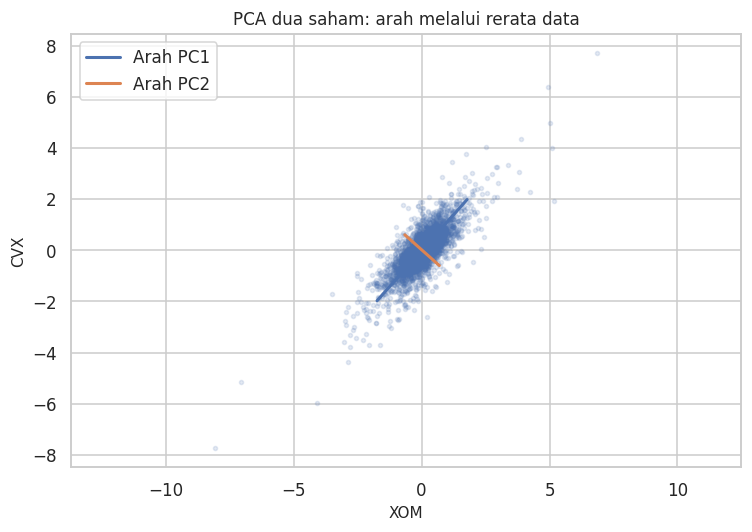

In [ ]:
pca_oil=PCA(n_components=2,svd_solver="full").fit(oil)
display(pd.DataFrame(pca_oil.components_,columns=oil.columns,index=["PC1","PC2"]))
display(pd.DataFrame({"eigenvalue":pca_oil.explained_variance_,"variance_ratio":pca_oil.explained_variance_ratio_},index=["PC1","PC2"]))
center=oil.mean().to_numpy()
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(oil.XOM,oil.CVX,s=7,alpha=.15)
for j,(direction,var) in enumerate(zip(pca_oil.components_,pca_oil.explained_variance_)):
    vector=direction*np.sqrt(var)*3
    ax.plot([center[0]-vector[0],center[0]+vector[0]],[center[1]-vector[1],center[1]+vector[1]],lw=2,label=f"Arah PC{j+1}")
ax.set(xlabel="XOM",ylabel="CVX",title="PCA dua saham: arah melalui rerata data")
ax.set_aspect("equal",adjustable="datalim");ax.legend();plt.tight_layout();plt.show()
centered=oil.to_numpy()-pca_oil.mean_
_,singular,vh=np.linalg.svd(centered,full_matrices=False)
assert np.allclose(singular**2/(len(oil)-1),pca_oil.explained_variance_)
assert np.allclose(pca_oil.components_ @ pca_oil.components_.T,np.eye(2))
print("Eigenvalue dari SVD sama dengan PCA; arah komponen ortonormal.")

Komponen untuk >=95% varians pada covariance mentah: 11
MSE rekonstruksi in-sample: 0.016945


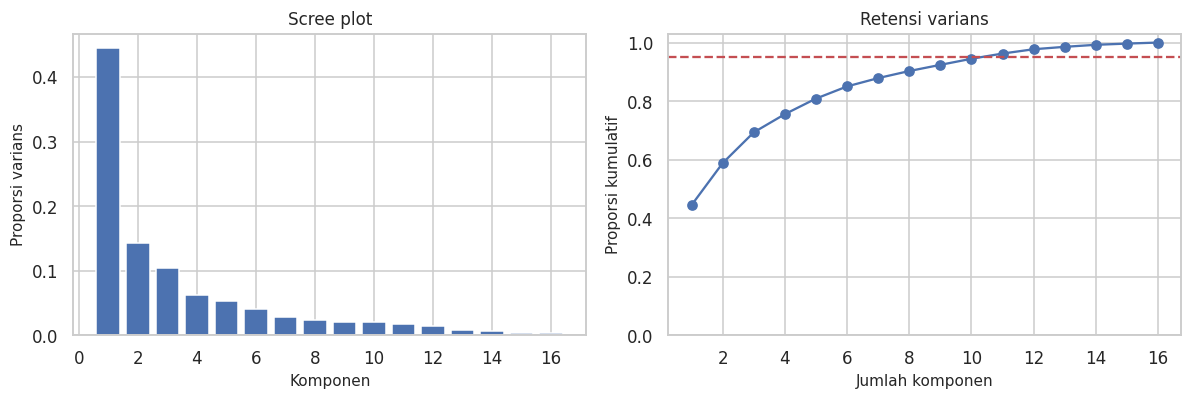

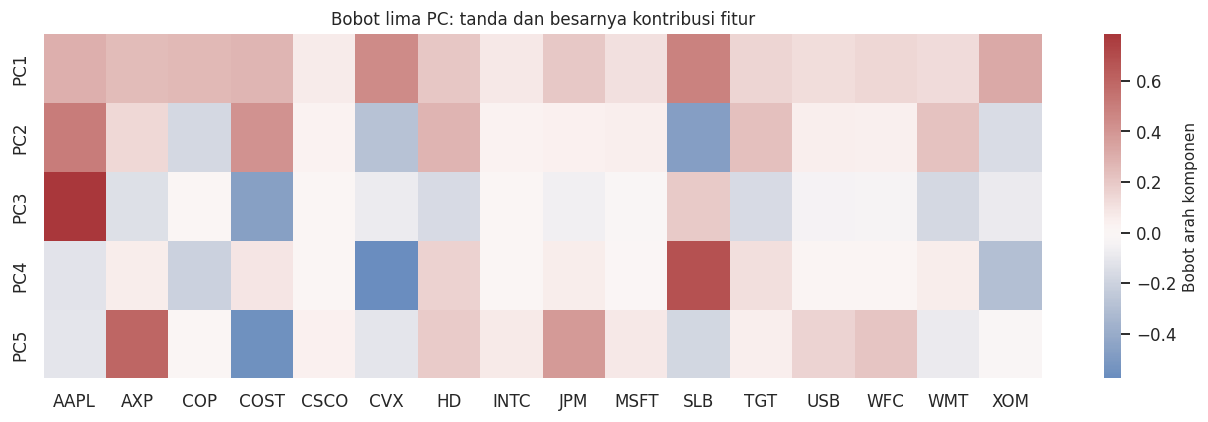

In [ ]:
pca=PCA(svd_solver="full").fit(top)
ratio=pca.explained_variance_ratio_;k95=int(np.searchsorted(np.cumsum(ratio),.95)+1)
print("Komponen untuk >=95% varians pada covariance mentah:",k95)
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
axes[0].bar(np.arange(1,len(ratio)+1),ratio);axes[0].set(xlabel="Komponen",ylabel="Proporsi varians",title="Scree plot")
axes[1].plot(np.arange(1,len(ratio)+1),np.cumsum(ratio),"o-");axes[1].axhline(.95,ls="--",color="C3");axes[1].set(xlabel="Jumlah komponen",ylabel="Proporsi kumulatif",ylim=(0,1.03),title="Retensi varians")
plt.tight_layout();plt.show()
loadings=pd.DataFrame(pca.components_[:5],columns=syms,index=[f"PC{i+1}" for i in range(5)])
fig,ax=plt.subplots(figsize=(12,4));sns.heatmap(loadings,cmap="vlag",center=0,ax=ax,cbar_kws={"label":"Bobot arah komponen"})
ax.set_title("Bobot lima PC: tanda dan besarnya kontribusi fitur")
plt.tight_layout();plt.show()
reduced=PCA(n_components=k95,svd_solver="full").fit(top)
reconstructed=reduced.inverse_transform(reduced.transform(top))
print("MSE rekonstruksi in-sample:",round(np.mean((top.to_numpy()-reconstructed)**2),6))

### 2.1 Correspondence analysis (CA)

CA menguraikan hubungan dalam tabel kontingensi nonnegatif. Dengan $P=N/n$, massa baris $r$ dan kolom $c$, matriks residual terstandar adalah

$$S=D_r^{-1/2}(P-rc^T)D_c^{-1/2}.$$

SVD $S=UDV^T$ menghasilkan koordinat principal baris $D_r^{-1/2}UD$ dan kolom $D_c^{-1/2}VD$. Inertia total $\sum d_j^2$ sama dengan statistik chi-square dibagi n. Seluruh baris/kolom harus mempunyai massa positif. Rank efektif paling tinggi $\min(I-1,J-1)$.

Jarak antarbaris berkaitan dengan perbedaan profil frekuensi dalam metrik chi-square; demikian pula antarkolom. Pada peta simetris, jarak langsung antara satu baris dan satu kolom **tidak** dapat dibaca sebagai jarak Euclidean asosiasi yang pasti. Arah dan profil membantu interpretasi, sedangkan dua dimensi hanya mempertahankan sebagian inertia.

Inertia total: 1.1149 | dipertahankan 2 dimensi: 0.886


,inertia,proporsi
Dim1,0.542889,0.486922
Dim2,0.445003,0.399127
Dim3,0.127048,0.113951


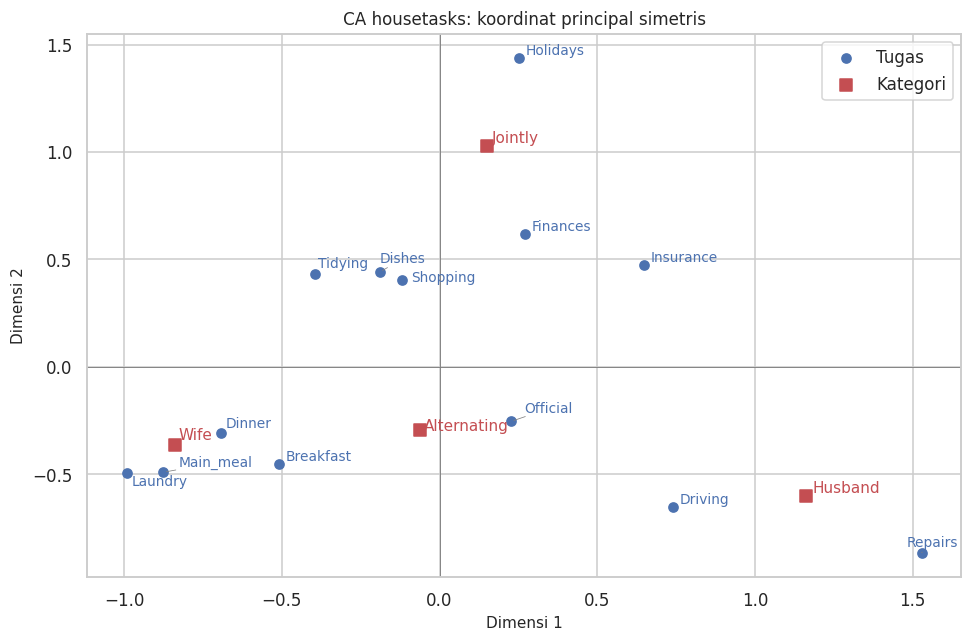

In [ ]:
N=tasks.to_numpy(dtype=float);n_total=N.sum();P=N/n_total
r=P.sum(axis=1);c=P.sum(axis=0)
assert np.all(N>=0) and np.all(r>0) and np.all(c>0)
S=(P-np.outer(r,c))/np.sqrt(np.outer(r,c))
U,D,Vt=np.linalg.svd(S,full_matrices=False)
rank=min(N.shape)-1
inertia=D[:rank]**2
row_coord=(U[:,:2]*D[:2])/np.sqrt(r[:,None])
col_coord=(Vt.T[:,:2]*D[:2])/np.sqrt(c[:,None])
chi2,_,_,_=chi2_contingency(N,correction=False)
assert np.isclose(inertia.sum(),chi2/n_total)
print("Inertia total:",round(inertia.sum(),4),"| dipertahankan 2 dimensi:",round(inertia[:2].sum()/inertia.sum(),4))
display(pd.DataFrame({"inertia":inertia,"proporsi":inertia/inertia.sum()},index=[f"Dim{i+1}" for i in range(rank)]))
fig,ax=plt.subplots(figsize=(9,6))
ax.scatter(row_coord[:,0],row_coord[:,1],c="C0",label="Tugas");ax.scatter(col_coord[:,0],col_coord[:,1],c="C3",marker="s",s=65,label="Kategori")
texts=[]
for name,xy in zip(tasks.index,row_coord):texts.append(ax.text(*xy,name,fontsize=9,color="C0"))
for name,xy in zip(tasks.columns,col_coord):texts.append(ax.text(*xy,name,fontsize=10,color="C3"))
adjust_text(texts,ax=ax,arrowprops=dict(arrowstyle="-",color="gray",lw=.5))
ax.axhline(0,color="gray",lw=.6);ax.axvline(0,color="gray",lw=.6)
ax.set(xlabel="Dimensi 1",ylabel="Dimensi 2",title="CA housetasks: koordinat principal simetris");ax.legend()
plt.tight_layout();plt.show()

## 3. K-means: objective, centroid dan algoritme

K-means meminimalkan within-cluster sum of squared distances:

$$\mathrm{WCSS}=\sum_{k=1}^{K}\sum_{i\in C_k}\|x_i-\mu_k\|^2.$$

Algoritme bergantian menugaskan setiap titik ke centroid terdekat dan memperbarui centroid menjadi rerata anggota. Solusi dapat berhenti pada minimum lokal; beberapa inisialisasi (`n_init=20`) dan seed eksplisit meningkatkan keterulangan. Cluster cocok untuk bentuk relatif kompak dalam metrik Euclidean; outlier atau kelompok dengan kepadatan sangat berbeda dapat mengganggu.

Pada contoh dua saham, empat cluster adalah kelompok **hari** dengan pola perubahan kedua saham. Nomor label dapat bertukar tanpa mengubah partisi. Centroid bukan titik pengamatan yang harus benar-benar ada.

Ukuran cluster: [297 187 105 291 251]


,XOM,CVX,jumlah_hari
0,0.961,1.377,179
1,-0.328,-0.567,374
2,0.243,0.336,466
3,-1.144,-1.750,112


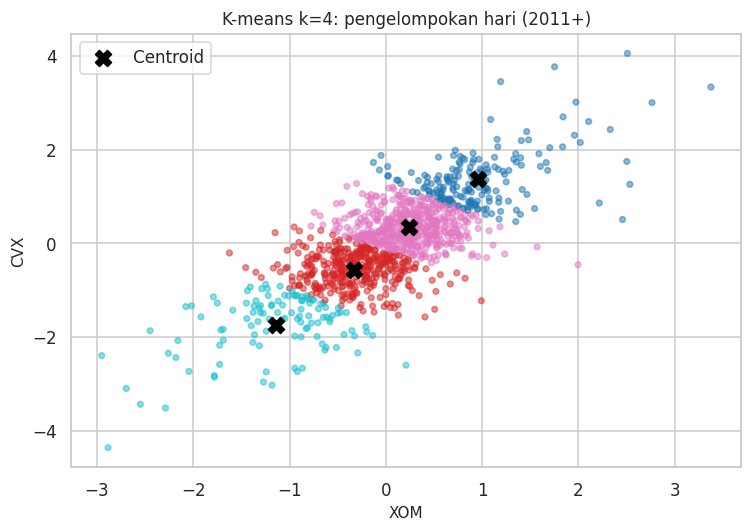

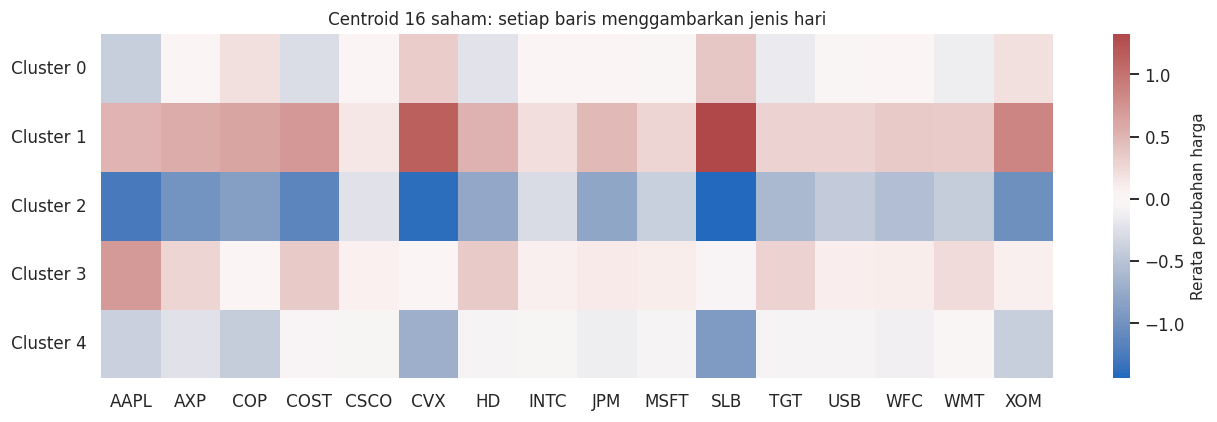

In [ ]:
km2=KMeans(n_clusters=4,n_init=20,random_state=SEED).fit(oil_recent)
centers2=pd.DataFrame(km2.cluster_centers_,columns=oil_recent.columns)
centers2["jumlah_hari"]=np.bincount(km2.labels_,minlength=4)
display(centers2.round(3))
fig,ax=plt.subplots(figsize=(7,5));ax.scatter(oil_recent.XOM,oil_recent.CVX,c=km2.labels_,cmap="tab10",s=14,alpha=.5)
ax.scatter(centers2.XOM,centers2.CVX,c="black",marker="X",s=110,label="Centroid")
ax.set(xlabel="XOM",ylabel="CVX",title="K-means k=4: pengelompokan hari (2011+)");ax.legend();plt.tight_layout();plt.show()
km16=KMeans(n_clusters=5,n_init=20,random_state=SEED).fit(top)
centers16=pd.DataFrame(km16.cluster_centers_,columns=syms,index=[f"Cluster {i}" for i in range(5)])
print("Ukuran cluster:",np.bincount(km16.labels_))
fig,ax=plt.subplots(figsize=(12,4));sns.heatmap(centers16,center=0,cmap="vlag",ax=ax,cbar_kws={"label":"Rerata perubahan harga"})
ax.set_title("Centroid 16 saham: setiap baris menggambarkan jenis hari")
plt.tight_layout();plt.show()

### 3.1 Memilih jumlah cluster dan mengecek stabilitas

Inertia selalu cenderung turun ketika k bertambah; penurunan itu sendiri bukan bukti bahwa semua cluster bermakna. Elbow mencari titik berkurangnya manfaat tambahan. Silhouette untuk satu titik adalah $(b-a)/\max(a,b)$, dengan a rerata jarak dalam cluster dan b rerata jarak terkecil ke cluster lain. Nilai tinggi berarti lebih kompak/terpisah dalam metrik tersebut, bukan label dunia nyata yang benar.

Sumber membagi inertia dengan jumlah cluster. Kita menampilkan **WCSS total** dan silhouette secara terpisah; `inertia/k` bukan rerata kuadrat jarak per observasi. Stabilitas terhadap seed diuji dengan Adjusted Rand Index (ARI), yang tidak terpengaruh pertukaran label. Ini stabilitas inisialisasi pada data sama, bukan validasi terhadap sampel baru. Bootstrap/subsampling dapat menguji jenis stabilitas yang lain.

,k,WCSS_total,WCSS_per_observation,silhouette,cluster_terkecil
0,2,6063.0956,5.3608,0.2202,449
1,3,5379.4522,4.7564,0.1577,242
2,4,4992.3960,4.4141,0.1226,204
3,5,4713.7557,4.1678,0.1079,105
4,6,4503.1250,3.9815,0.1063,106
5,7,4319.6579,3.8193,0.1059,81
6,8,4180.6308,3.6964,0.0987,70
7,9,4058.6913,3.5886,0.1021,67
8,10,3959.5641,3.5009,0.0999,34
9,11,3865.8379,3.4181,0.0849,40


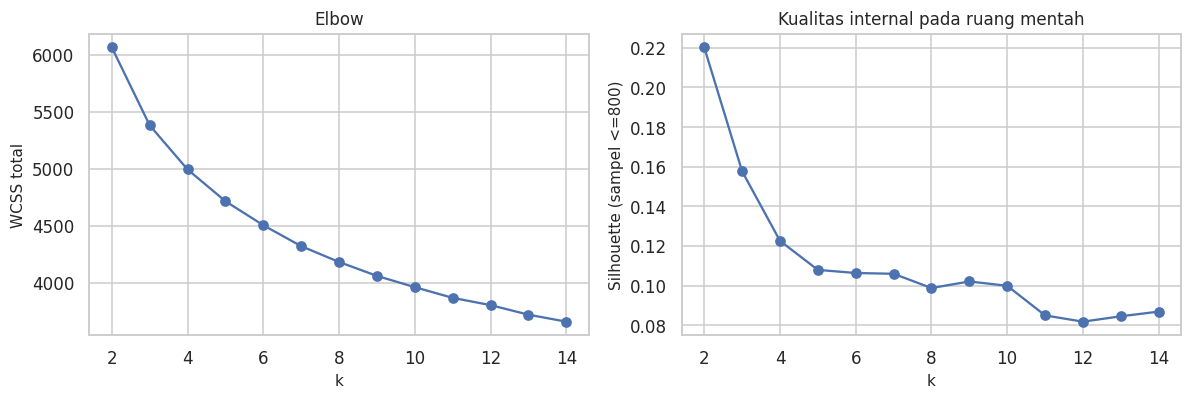

,0,42,99
0,1.000,0.966,0.873
42,0.966,1.000,0.898
99,0.873,0.898,1.000


In [ ]:
selection=[]
for k in range(2,15):
    m=KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(top)
    selection.append({"k":k,"WCSS_total":m.inertia_,"WCSS_per_observation":m.inertia_/len(top),"silhouette":silhouette_score(top,m.labels_,sample_size=min(800,len(top)),random_state=SEED),"cluster_terkecil":np.bincount(m.labels_).min()})
selection=pd.DataFrame(selection)
display(selection.round(4))
fig,axes=plt.subplots(1,2,figsize=(11,3.8));axes[0].plot(selection.k,selection.WCSS_total,"o-");axes[0].set(xlabel="k",ylabel="WCSS total",title="Elbow")
axes[1].plot(selection.k,selection.silhouette,"o-");axes[1].set(xlabel="k",ylabel="Silhouette (sampel <=800)",title="Kualitas internal pada ruang mentah")
plt.tight_layout();plt.show()
labels=[KMeans(n_clusters=5,n_init=20,random_state=seed).fit_predict(top) for seed in [0,42,99]]
stability=pd.DataFrame([[adjusted_rand_score(a,c) for c in labels] for a in labels],index=[0,42,99],columns=[0,42,99])
display(stability.round(3))

## 4. Hierarchical clustering

Agglomerative clustering mulai dari singleton, menggabungkan pasangan cluster terdekat, dan mengulang hingga terbentuk hierarki. Dendrogram menggambarkan urutan gabungan dan jarak/biaya penggabungan; garis tinggi tidak berarti waktu. Memotong pohon pada k kelompok merupakan keputusan eksploratif.

Single linkage memakai jarak pasangan terdekat (dapat membentuk rantai), complete terjauh (cenderung kompak), average rerata pasangan, dan Ward memilih kenaikan within-cluster sum of squares terkecil. **Ward memerlukan geometri Euclidean**, sehingga tidak dipakai pada Gower. Untuk Gower kita menggunakan average linkage.

Pada dendrogram saham, transpose mengubah objek menjadi saham. Complete linkage pada seri mentah sensitif terhadap skala/volatilitas. Kesamaan bentuk setelah standardisasi atau jarak korelasi menjawab pertanyaan berbeda dari kesamaan perubahan harga absolut.

Cluster 1 : COP, CVX, SLB, XOM
Cluster 2 : AAPL, AXP, COST, CSCO, HD, INTC, JPM, MSFT, TGT, USB, WFC, WMT
Cluster 3 : AMZN
Cluster 4 : GOOGL


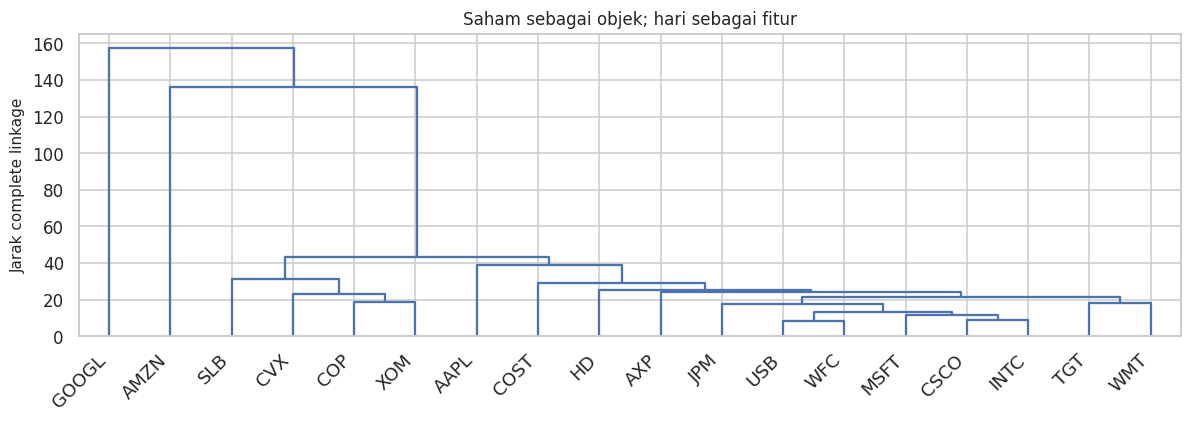

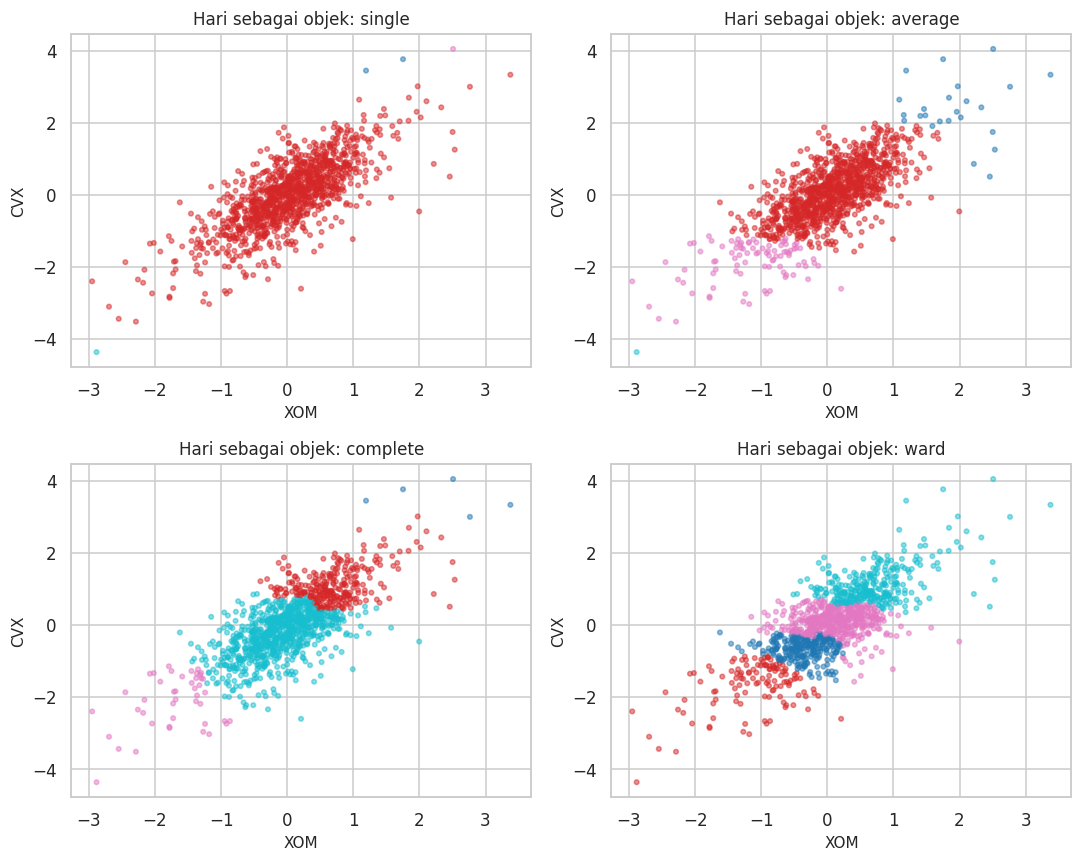

In [ ]:
stock_objects=stocks.loc["2011-01-01":,STOCKS].T
Z=linkage(stock_objects,method="complete",metric="euclidean")
fig,ax=plt.subplots(figsize=(11,4));dendrogram(Z,labels=stock_objects.index.tolist(),ax=ax,color_threshold=0)
ax.set(ylabel="Jarak complete linkage",title="Saham sebagai objek; hari sebagai fitur");plt.xticks(rotation=45,ha="right");plt.tight_layout();plt.show()
membership=pd.Series(fcluster(Z,t=4,criterion="maxclust"),index=stock_objects.index,name="cluster")
for group in sorted(membership.unique()):print("Cluster",group,":",", ".join(membership.index[membership==group]))
fig,axes=plt.subplots(2,2,figsize=(10,8))
for ax,method in zip(axes.flat,["single","average","complete","ward"]):
    zz=linkage(oil_recent,method=method)
    label=fcluster(zz,t=4,criterion="maxclust")
    ax.scatter(oil_recent.XOM,oil_recent.CVX,c=label,cmap="tab10",s=9,alpha=.5)
    ax.set(xlabel="XOM",ylabel="CVX",title=f"Hari sebagai objek: {method}")
plt.tight_layout();plt.show()

## 5. Model-based clustering dan Gaussian multivariat

Distribusi normal multivariat ditentukan rerata $\mu$ dan covariance $\Sigma$:

$$f(x)=(2\pi)^{-d/2}|\Sigma|^{-1/2}\exp[-\tfrac12(x-\mu)^T\Sigma^{-1}(x-\mu)].$$

Kontur dua dimensi berbentuk ellipse saat covariance tidak isotropik. Gaussian mixture menggabungkan beberapa komponen: $p(x)=\sum_k\pi_kN(x\mid\mu_k,\Sigma_k)$. Algoritme EM bergantian menghitung responsibility (keanggotaan probabilistik) dan memperbarui bobot/rerata/covariance. GMM memberikan soft assignment; K-means memberikan hard assignment berdasarkan jarak ke centroid.

Covariance `full` bebas per komponen, `tied` bersama, `diag` tanpa korelasi, dan `spherical` satu varians isotropik per komponen. Regularisasi covariance menghindari matriks singular. Komponen distribusi tidak selalu satu kelompok substantif; beberapa komponen mungkin hanya mengaproksimasi ekor distribusi.

Konvergen: True BIC: 4589.32
Covariance tiap komponen:
[[[0.271 0.278]
  [0.278 0.521]]

 [[0.987 0.994]
  [0.994 1.697]]]


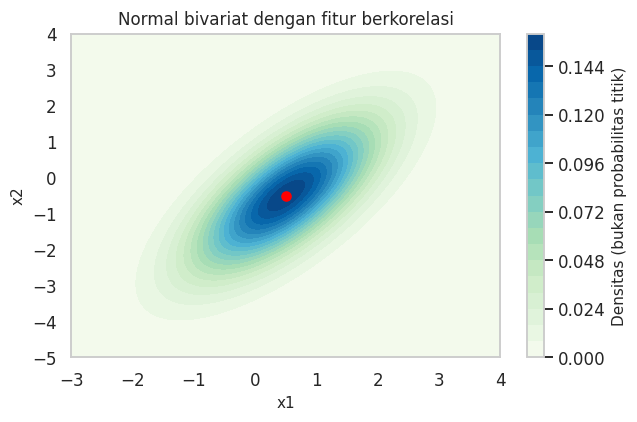

,XOM,CVX,weight
0,0.070916,0.102280,0.664527
1,-0.050749,-0.215395,0.335473


,P(komponen 0),P(komponen 1)
0,0.693810,0.306190
1,0.693075,0.306925
2,0.857358,0.142642
3,0.379651,0.620349
4,0.850187,0.149813


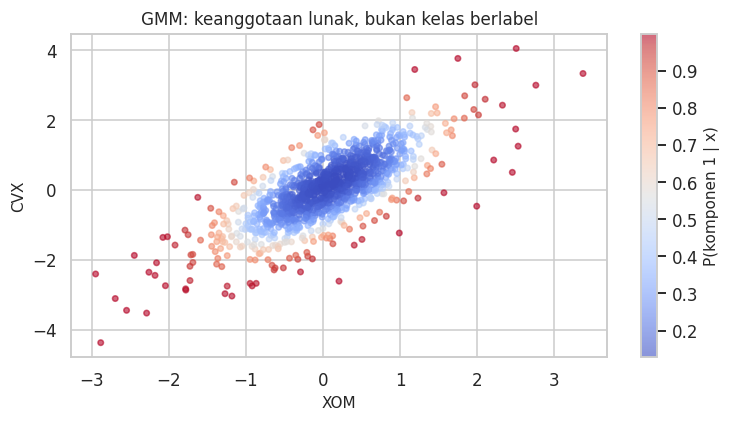

In [ ]:
mu=np.array([.5,-.5]);cov=np.array([[1.,1.],[1.,2.]])
x,y=np.meshgrid(np.linspace(-3,4,180),np.linspace(-5,4,180))
pos=np.dstack([x,y]);density=multivariate_normal(mean=mu,cov=cov).pdf(pos)
fig,ax=plt.subplots(figsize=(6,4));cf=ax.contourf(x,y,density,levels=20,cmap="GnBu");ax.scatter(*mu,c="red",s=35)
fig.colorbar(cf,ax=ax,label="Densitas (bukan probabilitas titik)");ax.set(xlabel="x1",ylabel="x2",title="Normal bivariat dengan fitur berkorelasi")
plt.tight_layout();plt.show()
gmm2=GaussianMixture(n_components=2,covariance_type="full",n_init=5,reg_covar=1e-6,random_state=SEED).fit(oil_recent)
print("Konvergen:",gmm2.converged_,"BIC:",round(gmm2.bic(oil_recent),2))
display(pd.DataFrame(gmm2.means_,columns=oil_recent.columns).assign(weight=gmm2.weights_))
print("Covariance tiap komponen:");print(gmm2.covariances_.round(3))
responsibility=gmm2.predict_proba(oil_recent)
assert np.allclose(responsibility.sum(axis=1),1)
display(pd.DataFrame(responsibility[:5],columns=["P(komponen 0)","P(komponen 1)"]))
fig,ax=plt.subplots(figsize=(7,4));sc=ax.scatter(oil_recent.XOM,oil_recent.CVX,c=responsibility[:,1],cmap="coolwarm",s=13,alpha=.6)
fig.colorbar(sc,ax=ax,label="P(komponen 1 | x)");ax.set(xlabel="XOM",ylabel="CVX",title="GMM: keanggotaan lunak, bukan kelas berlabel")
plt.tight_layout();plt.show()

### 5.1 Memilih jumlah komponen dengan BIC

$$\mathrm{BIC}=-2\log\hat L+k_{parameter}\log n.$$

BIC lebih kecil dipilih ketika dataset dan definisi likelihood sama. BIC memberi penalti kompleksitas tetapi tidak menjamin cluster merupakan kelompok nyata. Kita membandingkan 1–8 komponen dan empat struktur covariance, dengan seed dan beberapa inisialisasi. Nilai optimum di batas grid menandakan bahwa rentang grid masih perlu dievaluasi jika penelitian dilanjutkan. Ini pemilihan densitas eksploratif pada seluruh sampel; estimasi performa data baru memerlukan holdout/temporal validation yang terpisah.

Pilihan BIC eksploratif: {'k': 2, 'covariance': 'full', 'BIC': 4589.3203170532615, 'converged': True}


,k,covariance,BIC,converged
4,2,full,4589.32,True
8,3,full,4634.77,True
13,4,tied,4661.36,True
0,1,full,4662.48,True
1,1,tied,4662.48,True
12,4,full,4670.10,True
17,5,tied,4685.88,True
9,3,tied,4686.93,True


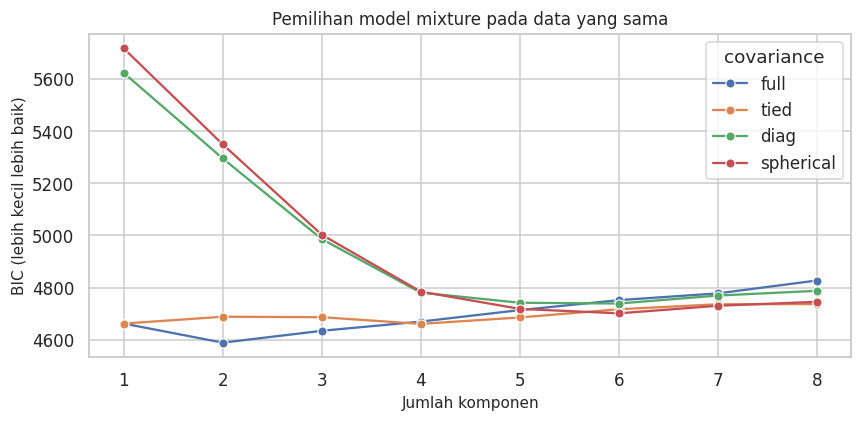

In [ ]:
bic_rows=[];gmm_candidates={}
for k in range(1,9):
    for covtype in ["full","tied","diag","spherical"]:
        m=GaussianMixture(n_components=k,covariance_type=covtype,n_init=3,max_iter=500,reg_covar=1e-6,random_state=SEED).fit(oil_recent)
        bic_rows.append({"k":k,"covariance":covtype,"BIC":m.bic(oil_recent),"converged":m.converged_})
        gmm_candidates[(k,covtype)]=m
bic_results=pd.DataFrame(bic_rows)
assert bic_results.converged.all(), "Ada GMM belum konvergen"
best_bic=bic_results.loc[bic_results.BIC.idxmin()]
display(bic_results.sort_values("BIC").head(8).round(2))
print("Pilihan BIC eksploratif:",best_bic.to_dict())
fig,ax=plt.subplots(figsize=(8,4));sns.lineplot(data=bic_results,x="k",y="BIC",hue="covariance",marker="o",ax=ax)
ax.set(xlabel="Jumlah komponen",ylabel="BIC (lebih kecil lebih baik)",title="Pemilihan model mixture pada data yang sama")
plt.tight_layout();plt.show()

## 6. Scaling, dominant variables, dan mixed data

### 6.1 Dampak satuan pada clustering

K-means meminimalkan jarak kuadrat. Pendapatan bernilai puluhan ribu bisa mendominasi rasio yang bernilai puluhan meskipun bukan variabel terpenting untuk pertanyaan analisis. Standardisasi memberi bobot skala yang lebih seimbang; robust scaling atau log transform dapat menjadi alternatif jika ekor panjang menjadi perhatian. Transformasi harus dijelaskan, karena setiap transformasi mengubah arti kedekatan.

Centroid standar dikembalikan ke satuan asal untuk interpretasi. Inertia mentah dan standar tidak dapat dibandingkan langsung karena satuannya berbeda. Semua observasi digunakan untuk eksplorasi subset default, sehingga tidak ada klaim akurasi test dari tabel centroid.

In [ ]:
defaults=loan.loc[loan.outcome=="default"].copy()
loan_cols=["loan_amnt","annual_inc","revol_bal","open_acc","dti","revol_util"]
raw=defaults[loan_cols]
scaler=StandardScaler().fit(raw);standard=scaler.transform(raw)
raw_km=KMeans(n_clusters=4,n_init=20,random_state=SEED).fit(raw)
scaled_km=KMeans(n_clusters=4,n_init=20,random_state=SEED).fit(standard)
raw_centers=pd.DataFrame(raw_km.cluster_centers_,columns=loan_cols).assign(size=np.bincount(raw_km.labels_))
scaled_centers=pd.DataFrame(scaler.inverse_transform(scaled_km.cluster_centers_),columns=loan_cols).assign(size=np.bincount(scaled_km.labels_))
print("Centroid ruang mentah");display(raw_centers.round(2))
print("Centroid setelah scaling, dikembalikan ke satuan asli");display(scaled_centers.round(2))
print("ARI partisi mentah vs standar:",round(adjusted_rand_score(raw_km.labels_,scaled_km.labels_),4))
print("Ukuran cluster terkecil mentah/standar:",np.bincount(raw_km.labels_).min(),np.bincount(scaled_km.labels_).min())

Centroid ruang mentah
Centroid setelah scaling, dikembalikan ke satuan asli
ARI partisi mentah vs standar: 0.1164
Ukuran cluster terkecil mentah/standar: 52 3717


,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,18291.67,83534.58,19682.92,11.66,16.78,62.29,7517
1,21877.72,165660.77,38910.23,12.61,13.47,63.61,1187
2,10611.34,42528.44,10286.72,9.59,17.71,58.11,13915
3,22570.19,489783.40,85161.35,13.33,6.91,59.65,52


,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,13316.07,55508.30,16318.91,14.22,24.22,59.50,6298
1,10512.18,51249.06,11576.71,7.48,15.80,77.83,7342
2,25916.95,116143.43,32776.02,12.45,16.25,66.06,3717
3,10328.44,53473.45,6030.05,8.66,11.26,30.83,5314


### 6.2 Dominant variables dalam PCA

Mengubah skala fitur mengubah PCA covariance. Pada 18 saham sejak 2005, kita membandingkan PCA mentah dan PCA standar dengan variabel yang sama. Fitur dengan volatilitas atau satuan besar dapat mendominasi arah komponen mentah. PCA standar tidak otomatis lebih benar; ia menjawab pertanyaan variasi relatif antarfitur, sedangkan PCA mentah mempertahankan besar variasi absolut.

Jika PCA dipakai sebelum model supervised, scaler dan PCA harus masuk pipeline yang dilatih hanya pada training fold. Pada notebook ini, fitting seluruh data sengaja dipakai untuk deskripsi sampel historis, bukan untuk evaluasi prediksi.

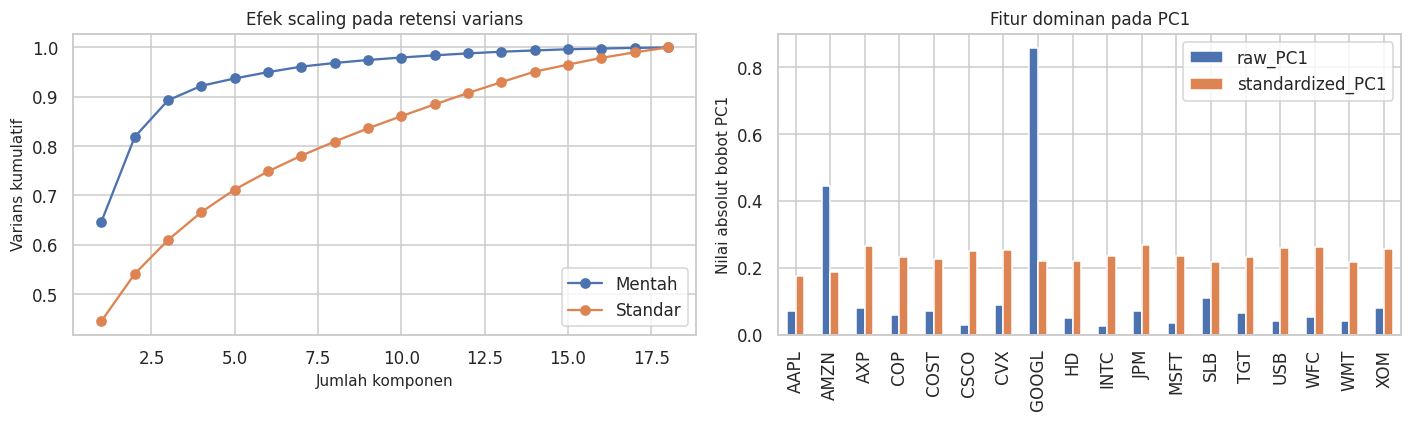

,raw_PC1,standardized_PC1
AAPL,0.072,0.176
AMZN,0.445,0.186
AXP,0.079,0.266
COP,0.058,0.232
COST,0.071,0.227
CSCO,0.029,0.252
CVX,0.090,0.253
GOOGL,0.857,0.220
HD,0.051,0.222
INTC,0.027,0.237


In [ ]:
wide=stocks.loc["2005-01-01":,STOCKS]
pca_raw=PCA(svd_solver="full").fit(wide)
pca_std=PCA(svd_solver="full").fit(StandardScaler().fit_transform(wide))
compare=pd.DataFrame({"raw_PC1":pca_raw.components_[0],"standardized_PC1":pca_std.components_[0]},index=STOCKS)
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].plot(np.arange(1,19),np.cumsum(pca_raw.explained_variance_ratio_),"o-",label="Mentah")
axes[0].plot(np.arange(1,19),np.cumsum(pca_std.explained_variance_ratio_),"o-",label="Standar");axes[0].legend();axes[0].set(xlabel="Jumlah komponen",ylabel="Varians kumulatif",title="Efek scaling pada retensi varians")
compare.abs().plot.bar(ax=axes[1]);axes[1].set(ylabel="Nilai absolut bobot PC1",title="Fitur dominan pada PC1")
plt.tight_layout();plt.show()
display(compare.round(3))

### 6.3 Gower's distance untuk data campuran

Gower menggabungkan kontribusi fitur numerik dan kategorikal dalam rentang 0–1. Untuk numerik, $d_j(i,l)=|x_{ij}-x_{lj}|/R_j$ dengan $R_j$ rentang fitur; untuk nominal, 0 jika sama dan 1 jika berbeda. Jarak total merupakan rata-rata berbobot kontribusi yang valid. Fitur konstan tidak menyumbang informasi sehingga dikeluarkan.

Implementasi berikut khusus **data lengkap**, bobot sama, dan kategori nominal simetris. Missing, ordinal, atau binary asymmetric memerlukan aturan tambahan; kode menolak missing agar tidak menyembunyikan asumsi. Rentang numerik sensitif outlier. Komputasi matriks jarak berbiaya memori kuadratik, sehingga contoh dibatasi 250 observasi.

Untuk `linkage`, matriks jarak persegi diubah menjadi condensed distance dengan `squareform`; memasukkan matriks persegi langsung akan salah ditafsirkan sebagai fitur observasi.

Lima contoh
Jumlah anggota: {1: 9, 2: 112, 3: 52, 4: 77}


,dti,payment_inc_ratio,home_,purpose_
0,24.94,5.03481,RENT,credit_card
1,19.75,2.44248,MORTGAGE,other
2,26.98,7.19760,RENT,debt_consolidation
3,13.04,6.74974,OWN,credit_card
4,13.01,14.39220,MORTGAGE,debt_consolidation


,0,1,2,3,4
0,0.000,0.573,0.294,0.359,0.713
1,0.573,0.000,0.617,0.607,0.461
2,0.294,0.617,0.000,0.606,0.449
3,0.359,0.607,0.606,0.000,0.604
4,0.713,0.461,0.449,0.604,0.000


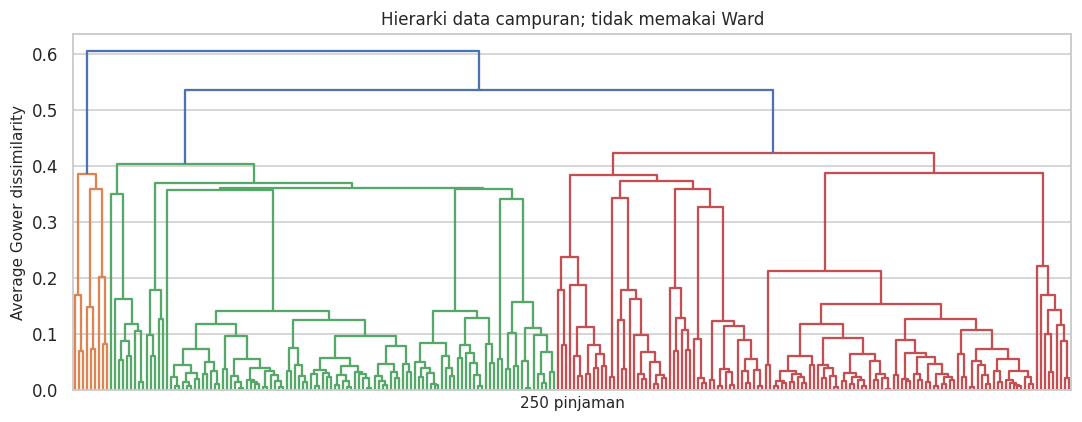

In [ ]:
def gower_complete(frame,numeric,categorical):
    if frame[numeric+categorical].isna().any().any():raise ValueError("Contoh ini hanya mendukung data lengkap")
    n=len(frame);D=np.zeros((n,n),dtype=float);used=0
    for col in numeric:
        v=frame[col].to_numpy(dtype=float);span=np.ptp(v)
        if span>0:D+=np.abs(v[:,None]-v[None,:])/span;used+=1
    for col in categorical:
        v=frame[col].astype(str).to_numpy()
        if len(np.unique(v))>1:D+=(v[:,None]!=v[None,:]).astype(float);used+=1
    if used==0:raise ValueError("Semua fitur konstan")
    return D/used
mixed_cols=["dti","payment_inc_ratio","home_","purpose_"]
mixed=loan.sample(n=250,random_state=SEED)[mixed_cols].reset_index(drop=True)
D=gower_complete(mixed,["dti","payment_inc_ratio"],["home_","purpose_"])
assert np.allclose(D,D.T) and np.allclose(np.diag(D),0) and D.min()>=0 and D.max()<=1
print("Lima contoh");display(mixed.head())
# Values below use ranges from the full 250-observation sample, not only five rows.
display(pd.DataFrame(D[:5,:5]).round(3))
Zg=linkage(squareform(D,checks=True),method="average")
fig,ax=plt.subplots(figsize=(10,4));dendrogram(Zg,no_labels=True,ax=ax)
ax.set(xlabel="250 pinjaman",ylabel="Average Gower dissimilarity",title="Hierarki data campuran; tidak memakai Ward")
plt.tight_layout();plt.show()
labels_g=fcluster(Zg,t=4,criterion="maxclust")
print("Jumlah anggota:",pd.Series(labels_g).value_counts().sort_index().to_dict())

### 6.4 Mengapa one-hot + standardisasi dapat bermasalah

Indikator kategori langka mempunyai simpangan baku kecil, sehingga standardisasi bisa memperbesar pengaruhnya. Variabel nominal dengan banyak level juga diwakili banyak kolom; bobot konseptual antarvariabel menjadi tidak seimbang. Centroid kolom one-hot adalah proporsi anggota kategori, bukan kategori orang sintetis yang pasti.

Contoh berikut mempertahankan kombinasi numerik dan dummy pada kode buku untuk memperlihatkan hasilnya. Keputusan menggunakan Gower, K-means one-hot, atau metode lain bergantung pada tipe variabel, arti kesamaan, dan tujuan. Ukuran cluster kecil serta dominasi kategori perlu diperiksa sebelum memberi nama atau mengambil tindakan.

In [ ]:
mixed_features=pd.get_dummies(defaults[["dti","payment_inc_ratio","home_","pub_rec_zero"]],dtype=float)
mixed_scaler=StandardScaler().fit(mixed_features)
mixed_standard=mixed_scaler.transform(mixed_features)
mixed_km=KMeans(n_clusters=4,n_init=20,random_state=SEED).fit(mixed_standard)
mixed_centers=pd.DataFrame(mixed_scaler.inverse_transform(mixed_km.cluster_centers_),columns=mixed_features.columns)
mixed_centers["jumlah"]=np.bincount(mixed_km.labels_)
display(mixed_centers.round(3))
print("Proporsi kategori home_ pada subset default:");display(defaults.home_.value_counts(normalize=True).to_frame("proporsi"))
print("Ingat: nomor cluster tidak menyatakan urutan risiko atau label kebenaran.")

Proporsi kategori home_ pada subset default:
Ingat: nomor cluster tidak menyatakan urutan risiko atau label kebenaran.


,dti,payment_inc_ratio,pub_rec_zero,home__MORTGAGE,home__OWN,home__RENT,jumlah
0,17.198,9.267,0.918,0.000,1.0,0.000,1888
1,17.456,8.423,1.000,1.000,-0.0,0.000,8857
2,16.505,8.064,-0.000,0.516,-0.0,0.484,1788
3,16.992,9.105,1.000,0.000,-0.0,1.000,10138


,proporsi
home_,
RENT,0.485378
MORTGAGE,0.431344
OWN,0.083278


## Analisis hasil eksekusi yang disertakan

- PCA XOM/CVX mempertahankan sekitar **89,59%** varians melalui PC1. Kedua saham bergerak bersama pada arah utama, sedangkan PC2 menggambarkan perbedaan relatif. Ini deskripsi covariance, bukan bukti hubungan sebab-akibat.
- Pada **1.131 hari** untuk 16 saham sejak 2011, dibutuhkan **11 komponen** untuk mempertahankan setidaknya 95% varians; MSE rekonstruksi in-sample sekitar **0,016945**. Dua komponen saja tidak mempertahankan seluruh variasi.
- Dua dimensi CA mempertahankan sekitar **88,60% inertia** tabel housetasks. Peta dua dimensi cukup informatif, tetapi masih menghilangkan sekitar 11,40% inertia.
- Pada grid k=2–14, silhouette terbesar sekitar **0,2202 pada k=2**; k=5 pada reproduksi hanya sekitar **0,1079**. Struktur kelompok tidak sangat terpisah pada ruang fitur mentah. Contoh k=5 dipertahankan untuk mempelajari centroid, bukan diklaim sebagai jumlah cluster optimal.
- Stabilitas k=5 terhadap tiga seed memberi ARI antarrun sekitar **0,873–0,966**: cukup konsisten tetapi tidak identik. Uji ini hanya mengubah inisialisasi, tidak mengubah sampel.
- BIC memilih **GMM dua komponen dengan covariance full**, sekitar **4.589,32**. Gambar menunjukkan komponen dengan sebaran berbeda di sekitar pola yang sama, sehingga jangan otomatis menamakannya dua kondisi ekonomi yang terpisah.
- Clustering pinjaman mentah menghasilkan cluster terkecil hanya **52** anggota; setelah scaling cluster terkecil **3.717**. ARI kedua partisi hanya **0,1164**, sehingga perubahan satuan/skala sangat memengaruhi hasil. Cluster kecil mentah mencerminkan profil nilai keuangan ekstrem, bukan otomatis anomali salah.
- Dalam PCA mentah 18 saham, bobot absolut PC1 GOOGL sekitar **0,857**, sedangkan setelah standardisasi sekitar **0,220**. Ini memperlihatkan dominasi varians absolut pada PCA mentah.

Angka berasal dari run 10 Oktober 2026 (WIB). Label cluster dapat bertukar, dan hasil eksplorasi ini belum diuji sebagai prediksi pada periode baru.

## Ringkasan chapter

PCA merangkum varians; CA merangkum asosiasi profil tabel kontingensi. K-means memberi centroid dan partisi; hierarchical clustering memberi struktur penggabungan; GMM memberi model densitas dan probabilitas keanggotaan. Setiap metode memakai definisi kesamaan dan asumsi yang berbeda. Inertia, silhouette, stabilitas, dan BIC membantu diagnosis tetapi bukan pengganti makna substantif. Scaling, satuan, periode data, outlier, tipe variabel, dan unit observasi dapat mengubah hasil secara besar. Jika hasil eksplorasi dipakai untuk prediksi atau keputusan pada data baru, diperlukan prosedur validasi tambahan.

## Refleksi mandiri

Jawab berdasarkan output dan pemahaman Anda; jangan sekadar menyalin rangkuman.

1. Berapa komponen diperlukan untuk mempertahankan 95% varians 16 saham, dan informasi apa yang masih hilang?
2. Jelaskan perbedaan objek yang dikelompokkan pada K-means saham dan dendrogram saham.
3. Apakah silhouette, elbow dan stabilitas mengarah ke keputusan yang sama? Mengapa tidak selalu ada satu k terbaik?
4. Apa perbedaan interpretasi responsibility GMM dan label K-means?
5. Bagaimana ukuran dan centroid cluster pinjaman berubah setelah scaling?
6. Mengapa average linkage dipakai untuk Gower, dan apa keterbatasan implementasi Gower notebook ini?

## Referensi

1. Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists*, 2nd ed. O’Reilly Media.
2. [Kode pendamping resmi dan lisensi](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa). Cakupan diverifikasi melalui kode chapter resmi; PDF pada tautan tugas tidak dapat dibaca melalui akses yang tersedia.
3. [Kode resmi Chapter 7](https://github.com/gedeck/practical-statistics-for-data-scientists/blob/8a6d3bb6468e979c861d4b37215e1413702dfdfa/python/code/Chapter%207%20-%20Unsupervised%20Learning.py).
4. [scikit-learn: PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca).
5. [scikit-learn: clustering](https://scikit-learn.org/stable/modules/clustering.html).
6. [scikit-learn: Gaussian mixture](https://scikit-learn.org/stable/modules/mixture.html).
7. [SciPy: hierarchical linkage](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html).